# Intelligente systemer: Maskinlæringsutfordringen
Velkommen til denne Jupyter notebooken, som du skal bruke til den obligatoriske innsendingsoppgaven i Høyskolen Kristianias emne «Utvikling og anvendelse av intelligente systemer».

## Hvordan du bruker denne notebooken 
Du skal gå gjennom denne notebooken for å løse innsendingsoppgaven. Undervis skal du skrive kode som løser kodeoppgavene skrevet _i kursiv_. Skriv kode inn i kodecellen rett under oppgaven, og legg gjerne til flere kodeceller. Du kan finne og gjenbruke relevant kode i notebooks i emnets modul 1, 2 og 3, og her i oppgaveteksten. Det er lov å løse oppgavene med andre programmeringsspråk, men alle kodehint er gitt for Python.

Underveis vil du også finne oppgaver du må besvare tekstlig. Også disse er skrevet _i kursiv_. De skal besvares i markdowncellene rett under oppgavene. Referer til egen kode der det er relevant.

Etter at du har lagt inn egen tekst og kode for hver oppgave, skal du levere inn en PDF-versjon av denne notebooken. PDF-en skal vise både den skriftlige besvarelsen din og output fra alle kodecellene. Du eksporterer notebooken fra JupyterLab via File-menyen -> Export Notebook as -> PDF. Alternativt kan du bruke File-menyen -> Print... I utskriftvinduet som kommer opp, velger du «Lagre som PDF» i feltet Destinasjon.

## Problemstilling: Predikere salg av matprodukter (fiktivt eksempel)
Du har fått i oppgave fra Indiske Matgrossisters Forening å utvikle en modell som skal predikere salg av produkter i forskjellige typer matbutikker. De ønsker en modell der de kan oppgi noen karakteristika for produktet og butikken, og så få et estimat for salget. Kunden, det vil si Indiske Matgrossisters Forening, har testdataene. Du får kun utlevert dataene som brukes til trening og validering.

_**Fritekstoppgave**:_

1. _Hva er en god baselinemodell for dette problemet?_

**Svar**:

Gjennomsnitts-salget er den enkleste baseline

## Pakker og nyttige funksjoner

In [1]:
# Du må først kjøre denne cellen for å importere relevante biblioteker

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import cross_validate
import seaborn as sns
from sklearn.preprocessing import StandardScaler,MinMaxScaler
from sklearn.metrics import mean_squared_error,r2_score
import xgboost as xgb

In [2]:
# Her er hjelpefunksjonene fra modul 1. Du må kjøre denne cellen for å bruke funksjonene.

def make_scatter_plot(data, para1, para2, logx=False, logy=False):
    plt.plot(data[para1], data[para2], '*', alpha=0.1)
    if logx:
        plt.xscale("log")
    if logy:
        plt.yscale('log')
    plt.xlabel(para1)
    plt.ylabel(para2)

def corr_heatmap(df, figsize=(10, 10)):
    _, axs = plt.subplots(figsize=figsize)
    ax = sns.heatmap(
        df, vmin=-1, vmax=1, cmap="BrBG", linewidths=0.5, annot=True, ax=axs)
    ax.set_title('Correlation matrix')
    return ax

def make_histogram(data, variable, binwidth, lower_lim=None, upper_lim=None):
    if upper_lim == None:
        upper_lim = data[variable].max()
    if lower_lim == None:
        lower_lim = data[variable].min()
    bins=np.arange(lower_lim, upper_lim + binwidth, binwidth)
    plt.hist(data[variable],bins=bins,edgecolor = 'black',alpha=0.75,range = [data[variable].min(),upper_lim])
    plt.ylabel("antall")
    plt.xlabel(variable)

## Dataene
Dataene er hentet fra 5000 matbutikker i India. Vi har disse variablene:
- **ProductID**: En ID som unikt identifiserer produktet. 
- **FatContent**: Om produktet har lavt fettinnhold eller ikke.
- **Visibility**: Hvor synlig produktet er i butikken. Er skalert til å være et tall mellom 0 og 1. 
- **StoreType**: Hva slags type butikk det er. I Norge ville dette ha tilsvart ulike kjeder.
- **Size Store**: Butikkens størrelse gitt som kategori.
- **MRP**: Maximum retail price (https://en.wikipedia.org/wiki/Maximum_retail_price). Merk at MRP kan være forskjellig for samme produkt, avhengig av hvor butikken ligger. 
- **Sales**: Totalt salg av gitt produkt i butikken. Valuta er rupi.

Hver kolonne i datasettet representerer det totale salget av et gitt produkt i en bestemt butikk i 2018.

In [3]:
# Vi laster dataene inn i en pandas dataframe. Deretter kan vi begynne å jobbe med dataene.

frame=pd.read_csv("data/sales_data.csv")

### Få oversikt over dataene
_**Kodeoppgave 1**:_
- _Få en rask oversikt over dataene._

> **Hint:** Her kan du gjerne bruke pandas' `describe`-funksjon, og du kan bruke `isna`-funksjonen for å finne `NaN`-verdier (dvs. verdier som er «Not a Number»). Koden kan f.eks. se slik ut:
>```
># For numeriske verdier (default setting er å ekskludere kategoriske variabler):
>frame.describe()
>
># For kategoriske verdier:
>frame.describe(exclude=[np.number])
>
># Finn NaN-verdier
>frame.isna().sum()
```

In [4]:
# Studentkode

# (Skriv din kode her. Lag gjerne flere kodeceller istedenfor å skrive all kode i én celle.)
frame.describe()

,Visibility,MRP,Sales
count,5000.000000,5000.000000,5000.000000
mean,-5.973329,141.344520,2188.381667
std,23.712860,62.401514,1703.131187
min,-99.000000,31.290000,33.290000
25%,0.026839,94.119250,846.231800
50%,0.054251,143.315400,1808.312800
75%,0.093850,186.472700,3091.975200
max,0.328391,266.888400,11445.102000


In [5]:
# Studentkode
frame.describe(exclude=[np.number])

,ProductID,FatContent,StoreType,SizeStore
count,5000,5000,5000,3561
unique,1538,5,4,3
top,DRE49,Low Fat,Supermarket Type1,Medium
freq,8,3008,3328,1605


In [6]:
# Studentkode
frame.isna().sum()

ProductID        0
FatContent       0
Visibility       0
StoreType        0
SizeStore     1439
MRP              0
Sales            0
dtype: int64

&nbsp;<br>
_**Fritekstoppgaver**:_

2. _Hvor mange datapunkter har vi?_
3. _Hva er gjennomsnittlig salgspris?_
4. _Hvor mange forskjellige ProductID har vi?_

**Svar**:

2. 5000 datapunkter

3. mean av MRP er 141.344520

4. 1538	unikke ProductID

### Utforsk variablene hver for seg
_**Kodeoppgave 2**:_
- _Utforsk alle variablene hver for seg._

>**Hint:**
>Du kan bruke funksjonen `frame.hist()`
>for å raskt lage histogrammer for de numeriske variablene, men bruk gjerne hjelpefunksjonene (som er lagt til toppen av notebooken) for å studere histogrammene i detalj.
>For de kategoriske variablene, er det lurt å bruke `value_counts(dropna=False)` istedenfor vanlig value counts, slik at du også får med verdier som er NaN.

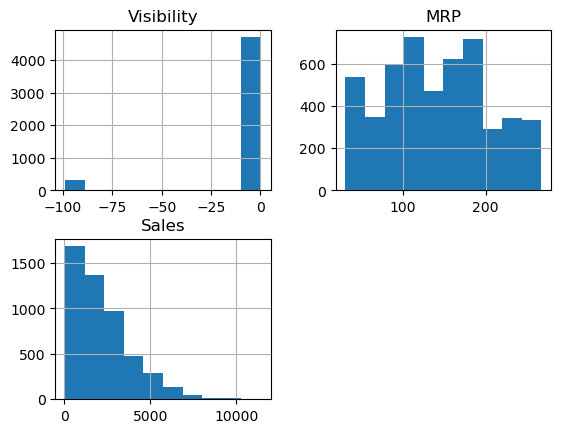

In [7]:
# Studentkode

# (Skriv din kode her. Lag gjerne flere kodeceller.)
frame.hist();

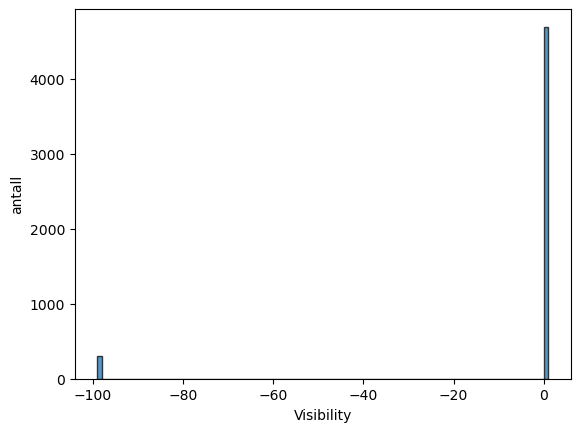

In [8]:
# Studentkode (de bør gjøre det samme for Sales og MRP også)
make_histogram(frame,"Visibility", 1, lower_lim=None, upper_lim=None)

In [9]:
# Studentkode (de skal gjøre det samme for 'ProductID', 'FatContent', 'StoreType', 'SizeStore')
display(frame["FatContent"].value_counts(dropna=False))
display(frame["ProductID"].value_counts(dropna=False))
display(frame["StoreType"].value_counts(dropna=False))
display(frame["SizeStore"].value_counts(dropna=False))

#for StoreType in frame.StoreType.unique():
#    print(StoreType)
#    display(frame[frame["StoreType"]==StoreType]["SizeStore"].value_counts(dropna=False))


FatContent
Low Fat    3008
Regular    1679
LF          183
reg          68
low fat      62
Name: count, dtype: int64

ProductID
DRE49    8
FDU23    8
FDR43    8
FDJ55    8
NCR53    7
        ..
FDZ55    1
FDR16    1
FDS07    1
FDO31    1
FDS36    1
Name: count, Length: 1538, dtype: int64

StoreType
Supermarket Type1    3328
Grocery Store         608
Supermarket Type3     538
Supermarket Type2     526
Name: count, dtype: int64

SizeStore
Medium    1605
NaN       1439
Small     1398
High       558
Name: count, dtype: int64

_**Fritekstoppgaver**:_

5. _Du bør nå ha funnet minst to (vi vet om tre) datakvalitetsproblemer. Beskriv dem._
6. _Du kan komme deg rundt et av datakvalitetsproblemene ved å rette opp det som er feil, hvis du har gode grunner til å anta hva det skal rettes til. Hvis du ikke kan gjøre noen slike antagelser, kan du fylle inn gjennomsnittet eller den mest vanlige verdien. Du kan også velge å fjerne alle rader med et gitt datakvalitetproblem. For hver av datakvalitetsproblemene, velg en strategi og begrunn hvorfor._
7. _Du skal ta vekk kolonnen for ProductID. Kan du forklare hvorfor?_

>**Hint 1**: To av problemene har med manglende verdier å gjøre, og ett har med skrivemåter å gjøre.
>
>**Hint 2**:
Nyttige pandas-funksjoner:
>```
># Erstatt et ord med et annet. Kan også brukes for numeriske verdier.
>frame[variabel].replace({"ord1":"nyttord1","ord2":"nyttord2"},inplace=True)
>
># Erstatt NaN-verdier
>frame[variabel].fillna(<tall eller ord som erstatter NaN>,inplace=True)
>
># Ta vekk alle datapunkter som ikke tilfredstiller et krav
>frame=frame[frame[variabel]!=4]
>
># Dropp alle kolonner som inneholder NaN
>frame.dropna(inplace=True)
>
># Dropp en kolonne
>frame.drop(columns=[variabel],inplace=True)
>```

**Svar**:

5. a) Negative visibility. b) Mange nan i SizeStore. c) Ulike stavemåter for Low Fat/low fat og Regular/reg. 

6. a) Enten antar du at visibility er negativ fordi den ikke var målt for den varen og så fjerner du rekkene med nan, eller du antar at negativ visibility er det samme som null og setter de til null. b) Enten antar du at nan for SizeStore er fordi den er noe annet enn det som er vanlig og fjerner de, eller også antar du at den vanligste verdi for hver StoreType er det korrekte og erstatter/imputerer. Dette medfører en risiko for å forurense datasettet. c) Erstatt reg med Regular og low fat med Low Fat.  

7) Det er en kategorisk variabel med mange verdier som er vanskelig å one-hot-encode. I tillegg er det mange ID som bare er representert en gang og dermed gir kolonnen veldig lite informasjon.

In [10]:
cleanframe = frame.copy()
cleanframe['FatContent'].replace({"reg": "Regular", "low fat": "Low Fat", "LF":"Low Fat"}, inplace=True)
cleanframe = cleanframe[cleanframe['Visibility']>=0]
cleanframe = cleanframe.drop(columns=['ProductID'])
cleanframe = cleanframe.dropna(subset=['SizeStore'])

In [11]:
cleanframe

,FatContent,Visibility,StoreType,SizeStore,MRP,Sales
0,Low Fat,0.016047,Supermarket Type1,Medium,249.8092,3735.1380
1,Regular,0.019278,Supermarket Type2,Medium,48.2692,443.4228
2,Low Fat,0.016760,Supermarket Type1,Medium,141.6180,2097.2700
6,Regular,0.012741,Supermarket Type1,High,57.6588,343.5528
7,Low Fat,0.127470,Supermarket Type3,Medium,107.7622,4022.7636
...,...,...,...,...,...,...
4994,Low Fat,0.010382,Supermarket Type1,Medium,207.8954,2292.3494
4996,Low Fat,0.027059,Supermarket Type1,Small,153.3682,914.8092
4997,Regular,0.126200,Supermarket Type2,Medium,178.4028,1239.7196
4998,Regular,0.119462,Supermarket Type1,Small,182.7976,1810.9760


### Sjekk korrelasjoner
_**Kodeoppgave 3**:_
- _Sjekk korrelasjoner mellom den avhengige og de uavhengige variabelene._

> **Hint 1**: For å finne korrelasjoner mellom numeriske variabler, er det standard å bruke Pearsons korrelasjonskoeffisient. Denne metoden finner kun linære sammenhenger, men er et godt utgangspunkt. Se notebook i modul 1 for kode.
>
> **Hint 2**: For å finne korrelasjoner mellom kategoriske variabler og den avhengige variabelen, har vi ikke en like god standard. Men en enkel måte å se om en kategorisk variabel påvirker den avhengige variabelen, er å lage et såkalt boksplott for variabelen og se nærmere på de enkelte kategoriene. Generelt viser et slikt boksplott hvordan verdier i et utvalg fordeler seg, med maksverdi, minverdi, medianverdi, 25-persentil og 75-persentil. I vårt tilfelle kan vi tegne opp kategoriene for hver uavhengig variabel, stilt opp mot den avhengige variabelen _Sales_. Hvis vi ser at distribusjonen til _Sales_-dataene for en uavhengig variabel er ganske ulik for de forskjellige kategoriene, er det sannsynlig at denne variabelen påvirker _Sales_.
>
> **Hint 3**: Her er et eksempel på hvordan man lager boksplott for de forskjellige butikkstørrelsene:
>```
>sns.boxplot(x="SizeStore", y="Sales", data=frame)
>```

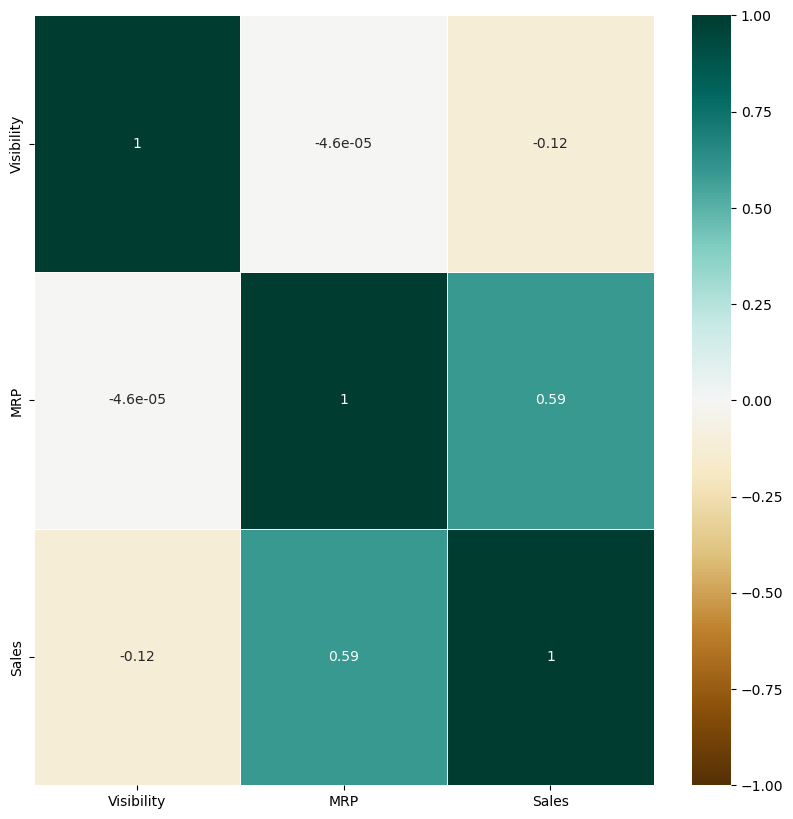

In [24]:
def corr_heatmap(df, figsize=(10, 10)):
    _, axs = plt.subplots(figsize=figsize)
    ax = sns.heatmap(df, vmin=-1, vmax=1, cmap="BrBG", linewidths=0.5, annot=True, ax=axs)
#    ax.set_title('Correlation matrix')
    return ax

corr_heatmap(frame[['Visibility', 'MRP', 'Sales']].corr());


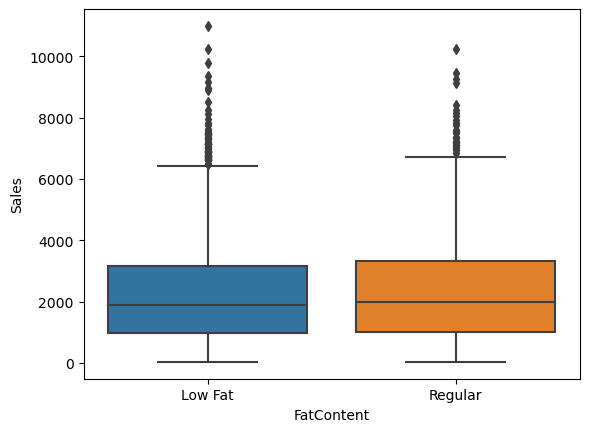

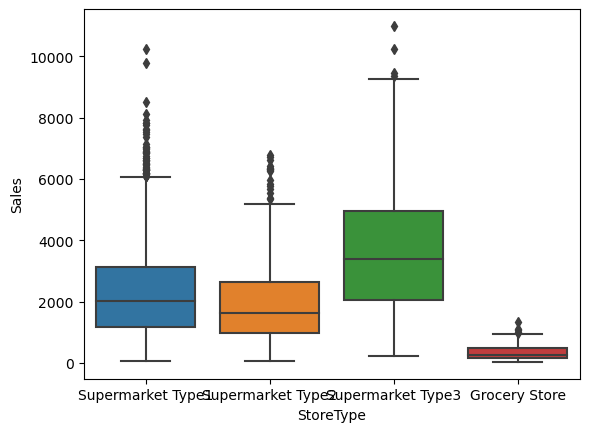

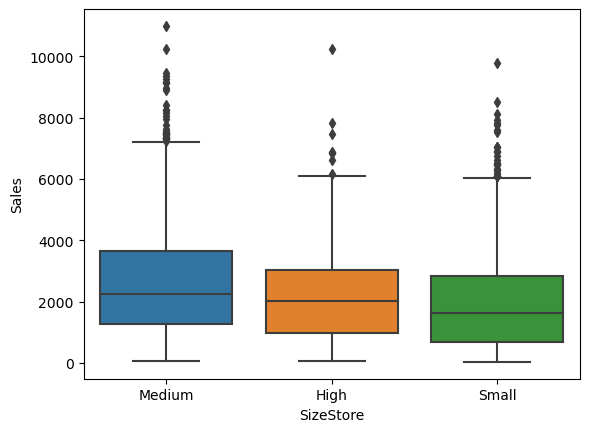

In [13]:
# Studentkode

# (Skriv din kode her. Lag gjerne flere kodeceller.)

# Studentene skal gjøre det samme for FatContent, StoreType, SizeStore
sns.boxplot(x="FatContent", y="Sales", data=cleanframe)
plt.show()
sns.boxplot(x="StoreType", y="Sales", data=cleanframe)
plt.show()
sns.boxplot(x="SizeStore", y="Sales", data=cleanframe)
plt.show()

_**Fritekstoppgave**:_

8. _Hvilke variabler tror du kan komme til å påvirke salget basert på den analysen du har gjort? Begrunn svaret ditt._

**Svar**:
Sales content som funksjon av Fat Content har veldig lite variasjon og dermed lite betydning (medmindre den er korrelert med andre variable).
Storetype har mest variasjon av de kategoriske variabler og dermed sannsynligvis større påvirkning. SizeStore har noe variasjon. Fra korrelasjons-matrisen har MRP mye høyere korrelasjon med sales enn Visibility.


## Modell

Du skal nå trene en modell som bruker informasjon om et produkt og en butikk til å predikere salget av det produktet i den butikken. Du skal benytte XGBoost og kan starte med å bruke alle de uavhenige variablene (unntatt ProductID, som du allerede har utelukket). Notebook 2 fra modul 2 inneholder både forklaring og eksempel på bruk av XGBoost. Før du trener modellen, må du splitte opp dataene og preprossere dem.

_**Kodeoppgave 4**:_
- _Del inn i trenings- og valideringsdata, og gjør preprosessering av data._

> **Hint**: Tenk på hvilke typer av preprosessering du trenger å gjøre på dataene. Beskrivelse av preprosessering finner du i notebooken til modul 3. I dette tilfellet er det helt greit å gjøre en-hot-koding (one-hot encoding) med den enkle koden vist nedenfor. Det er også greit å gjøre det før du deler opp data, fordi vi antar at alle kategorier vil være representert i både trenings-, validerings- og testdataene.
>```
>frame_processed=pd.get_dummies(frame)
>```

In [14]:
# Studentkode

# (Skriv din kode her. Lag gjerne flere kodeceller.)
frame = cleanframe
frame_processed=pd.get_dummies(frame)
X_train, X_eval, y_train, y_eval = train_test_split(
    frame_processed.drop(columns="Sales"), frame["Sales"], test_size=0.20, random_state=1)
scalerX = MinMaxScaler()
# Merk her at vi skalerer med X_train og senere bruker den til å transformere evaluering
scalerX.fit(X_train)
X_train = scalerX.transform(X_train)
X_eval = scalerX.transform(X_eval)
frame_processed

,Visibility,MRP,Sales,FatContent_Low Fat,FatContent_Regular,StoreType_Grocery Store,StoreType_Supermarket Type1,StoreType_Supermarket Type2,StoreType_Supermarket Type3,SizeStore_High,SizeStore_Medium,SizeStore_Small
0,0.016047,249.8092,3735.1380,True,False,False,True,False,False,False,True,False
1,0.019278,48.2692,443.4228,False,True,False,False,True,False,False,True,False
2,0.016760,141.6180,2097.2700,True,False,False,True,False,False,False,True,False
6,0.012741,57.6588,343.5528,False,True,False,True,False,False,True,False,False
7,0.127470,107.7622,4022.7636,True,False,False,False,False,True,False,True,False
...,...,...,...,...,...,...,...,...,...,...,...,...
4994,0.010382,207.8954,2292.3494,True,False,False,True,False,False,False,True,False
4996,0.027059,153.3682,914.8092,True,False,False,True,False,False,False,False,True
4997,0.126200,178.4028,1239.7196,False,True,False,False,True,False,False,True,False
4998,0.119462,182.7976,1810.9760,False,True,False,True,False,False,False,False,True


### XGBoost-modell
Når du nå skal lage en XGBoost-modell, kan du starte med å bruke standardverdier for flest mulig av hyperparameterene. Det eneste du skal ta stilling til, er dybden på træerne og evalueringsmetrikken. Her er et kode-eksempel uten hyperparameter-verdier:
```
params = {'max_depth': , 'objective': }
xgb_model = xgb.train(params=params, 
                       dtrain=xgb.DMatrix(X_train, label=y_train))
predicted = xgb_model.predict(xgb.DMatrix(X_eval))
```

_**Kodeoppgave 5**:_
- _Plott prediksjonene og y_eval for å sjekke at modellen predikerer meningsfylt._

> Hint: Du kan f.eks. bruke følgende kode:
> ```
> x = range(len(y_eval))
> plt.scatter(x, y_eval, label='y_eval')
> plt.scatter(x, predicted, label='predicted')
> plt.legend()
> ```

In [15]:
# Studentkode

# (Skriv din kode her. Lag gjerne flere kodeceller.)

params = {'max_depth': 6, 'objective':'reg:squarederror'}
xgb_model = xgb.train(params=params, 
                       dtrain=xgb.DMatrix(X_train, label=y_train))
predicted = xgb_model.predict(xgb.DMatrix(X_eval))

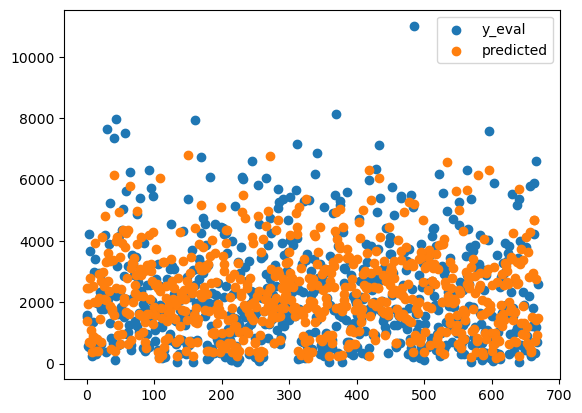

In [16]:
#studentkode
x = range(len(y_eval))
plt.scatter(x, y_eval, label='y_eval')
plt.scatter(x, predicted, label='predicted')
plt.legend()

## Modell-evaluering
_**Kodeoppgave 6**:_
- _Evaluer modellen din med RMSE og R2._

> Hint: Du kan benytte funksjonene `mean_squared_error` og `r2_score` fra scikit-learn som vi lastet inn på starten. Se eksempler i modul 3.

In [17]:
# Studentkode

# (Skriv din kode her. Lag gjerne flere kodeceller.)

print("RMSE trening", np.sqrt(mean_squared_error(y_train, xgb_model.predict(xgb.DMatrix(X_train)))))
print("RMSE validering",np.sqrt(mean_squared_error(y_eval, predicted)))

print("R2 trening", r2_score(y_train, xgb_model.predict(xgb.DMatrix(X_train))))
print("R2 validering", r2_score(y_eval, predicted))

RMSE trening 972.8055762932437
RMSE validering 1146.5228038130676
R2 trening 0.6798830471076565
R2 validering 0.553801876232657


_**Fritekstoppgaver**:_

9. _Beskriv minst én fordel og én ulempe ved XGBoost._
10. _Forklar forskjellen på RMSE og R2._
11. _Fungerte modellen like godt på valideringsdataene som på treningsdataene? Hvis ikke, forklar hvorfor. Kan du bruke dette til å forbedre modellen?_ 

**Svar**:

9. XGBoost er rask å trene og gir ofte bra resultater. Fordelen med tre-baserte modeller er større grad av forklarbarhet. Ulempen er at de ikke kan justeres og må trenes fra scratch hver gang vi legger til ny data. XGBoost kan også bare trenes med een output, hvilket er upraktisk dersom oppgaven f.eks. hadde vært å predikere salg samt hvilken måned salget var størst i.
10. RMSE The average of the squares of the errors—that is, the average squared difference between the estimated values and the actual value (wikipedia). R2 is the proportion of the variation in the dependent variable that is predictable from the independent variable(s). (wikipedia)
11. Modellen fungerer litt dårligere på valideringsdata enn på testdata. Sannsynligvis på grund av overfitting eller mangel på evne til å generalisere. Vi kan tune på hyperparameterene for å prøve å få de to verdier så nær hverandre som mulig.

### Eksperimenter med å ta vekk variabler
_**Kodeoppgave 7**:_
- _Forsøk å ta vekk variabler du tror ikke er signifikante basert på den utforskende analysen._

> Hint: Du finner eksempler i modul 3.

In [18]:
# Studentkode

# (Skriv din kode her. Lag gjerne flere kodeceller.)

frame_processed=frame[["StoreType","MRP","Sales"]]
frame_processed=pd.get_dummies(frame_processed)
X_train, X_eval, y_train, y_eval = train_test_split(
    frame_processed.drop(columns="Sales"), frame["Sales"], test_size=0.20, random_state=1)
scalerX = MinMaxScaler()
# Mer her at vi skalerer med X_train og bruker den senere til å transformere evaluering
scalerX.fit(X_train)
X_train = scalerX.transform(X_train)
X_eval = scalerX.transform(X_eval)

In [19]:
# Studentkode
params = {'max_depth': 3, 'objective':'reg:squarederror'}
xgb_model = xgb.train(params=params, 
                       dtrain=xgb.DMatrix(X_train, label=y_train))
predicted = xgb_model.predict(xgb.DMatrix(X_eval))

In [20]:
# Studentkode
print("RMSE trening", np.sqrt(mean_squared_error(y_train, xgb_model.predict(xgb.DMatrix(X_train)))))
print("RMSE validering",np.sqrt(mean_squared_error(y_eval, predicted)))
print("R2 trening", r2_score(y_train, xgb_model.predict(xgb.DMatrix(X_train))))
print("R2 validering", r2_score(y_eval, predicted))


RMSE trening 1086.845228145755
RMSE validering 1122.841651955432
R2 trening 0.600430824604923
R2 validering 0.5720437487681268


_**Fritekstoppgaver**:_

12. _Bør du ta vekk variablene som du tenkte ikke var signifikante?_

13. _Hva kan gjøres for å forbedre modellen? Beskriv med ord._


**Svar**:

12. Modellen blir ikke dårligere uten de dvs. de kan fjernes.

13. Hyperparameter tuning (e.g. max depth på 3 gir lavere RMSE på validering, men ikke på trening). Mer data.




Interpreting RMSE & R2

RMSE
One way to assess how well a regression model fits a dataset is to calculate the root mean square error, which is a metric that tells us the average distance between the predicted values from the model and the actual values in the dataset. The lower the RMSE, the better a given model is able to “fit” a dataset.

R2
The most common interpretation of r-squared is how well the regression model fits the observed data. For example, an r-squared of 60% reveals that 60% of the data fit the regression model. Generally, a higher r-squared indicates a better fit for the model.
